## Test training


In [1]:
%load_ext autoreload
%autoreload 1

import os
os.environ["QUANTDATA_EXPERIMENTS"]="/media/storage/quantdata/experiments"

from cdxcore.verbose import Context
verbose = Context("all")
with verbose.write_t("Importing torch...", end='') as tme:   
    import torch
    verbose.write(f"done; this took {tme}.", head=False)

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.torch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler

from quantdata.dysanos.simple.sampler import SimpleSampler, SimpleConfig, SamplingConfig, ExpiryFilter, RawDayFilter, SampleDaysConfig, DateRange, PoolConfig
from cdxcore.verbose import Context
from datetime import date

def test():
    simple_config = SimpleConfig(
            tickers = ['SPX','NDX','RUT'],
            date_range = DateRange(start=date(2015, 1, 1), end=date(2025, 7, 1)),
            raw_day_filter = RawDayFilter(),
            expiry_filter = ExpiryFilter(),
            sample_days_config = SampleDaysConfig(),
            sampling_config = SamplingConfig(num_samples=20)
    )
    pool_config = PoolConfig(num_workers=4, threading=False) # no parallel processing for testing
    verbose = Context.all
    sampler = SimpleSampler(simple_config=simple_config, pool_config=pool_config, verbose=verbose)
    return sampler

sampler = test()
print("/done")

00: Importing torch...done; this took 0.71s.
00: Generating samples for 3 tickers NDX, RUT and SPX with from 2015-01-01 to 2025-07-01... done; this took 0.75s.
00: Found the following number of samples per ticker: NDX: 2617, RUT: 2617 and SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker NDX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
01:   Ticker RUT: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 1233 training samples and 309 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken

## Training a simple MLP

/model created.
00: Trainer for 'AEC viz_train_sqrtVar_fit_sqrtVar 0f5837ec6b870a6d' on data 0f5837ec6b870a6d
00: =========================================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/0f5837ec6b870a6d/v1/viz_train_sqrtVar_fit_sqrtVar ed3385ea/last.pt'... done; this took 0.06s.
01:   Model is ready. Current epoch to train is 1010.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/0f5837ec6b870a6d/v1/viz_train_sqrtVar_fit_sqrtVar ed3385ea/.
00: Launching 'AEC viz_train_sqrtVar_fit_sqrtVar 0f5837ec6b870a6d' training for 1020 epochs over 1233 training and 309 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 2048 for valuation. The model has 31809 parameters. Resuming from epoch 1010.
00: Training 'viz_train_sqrtVar_fit_sqrtVar' epoch 1011/1020 error avg trn 0.0007152; val 0.0007161/0.001594 [30s 2s 0.51s]. LR: 

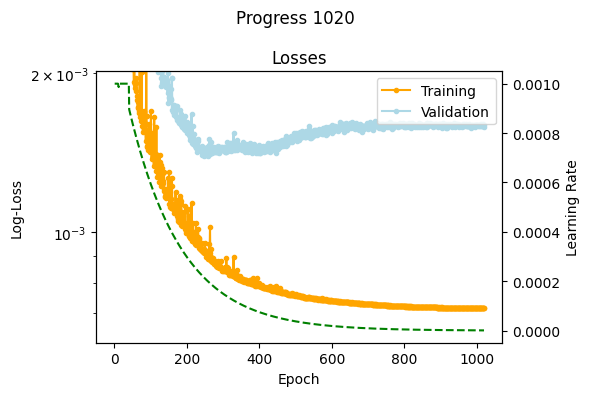

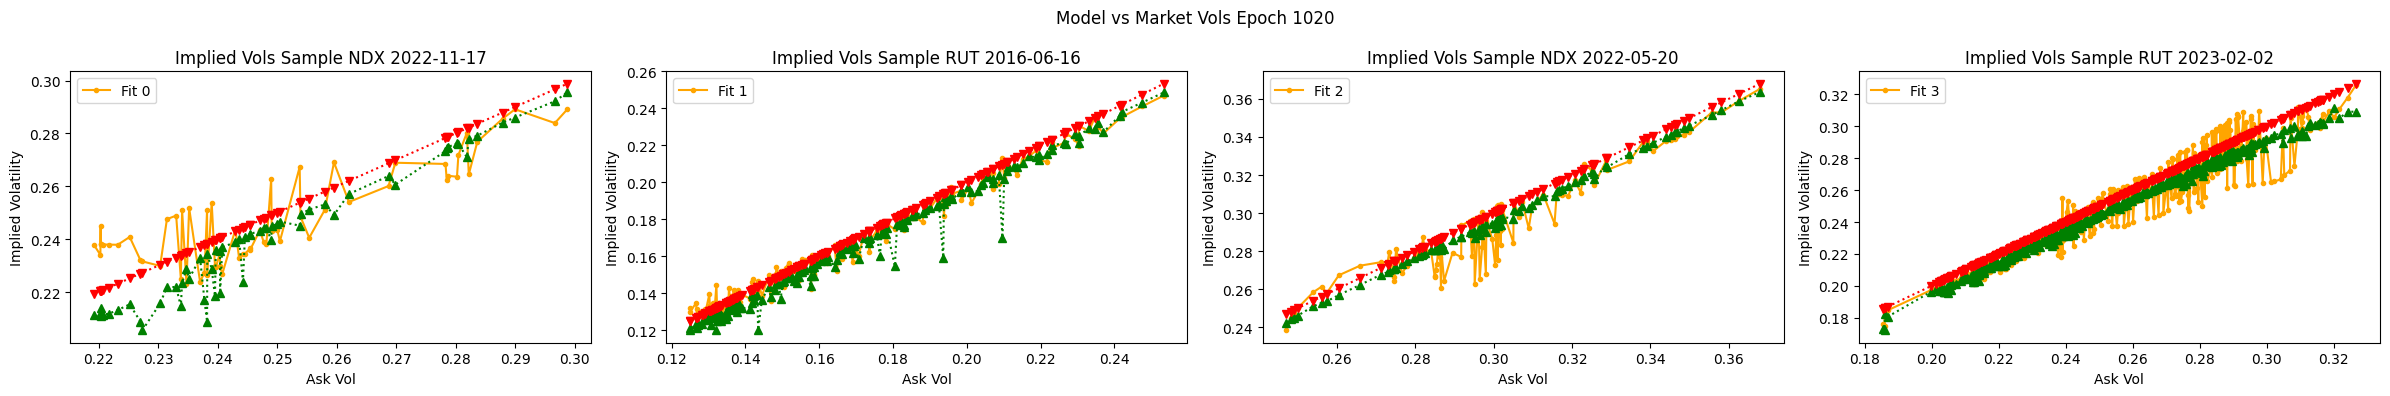

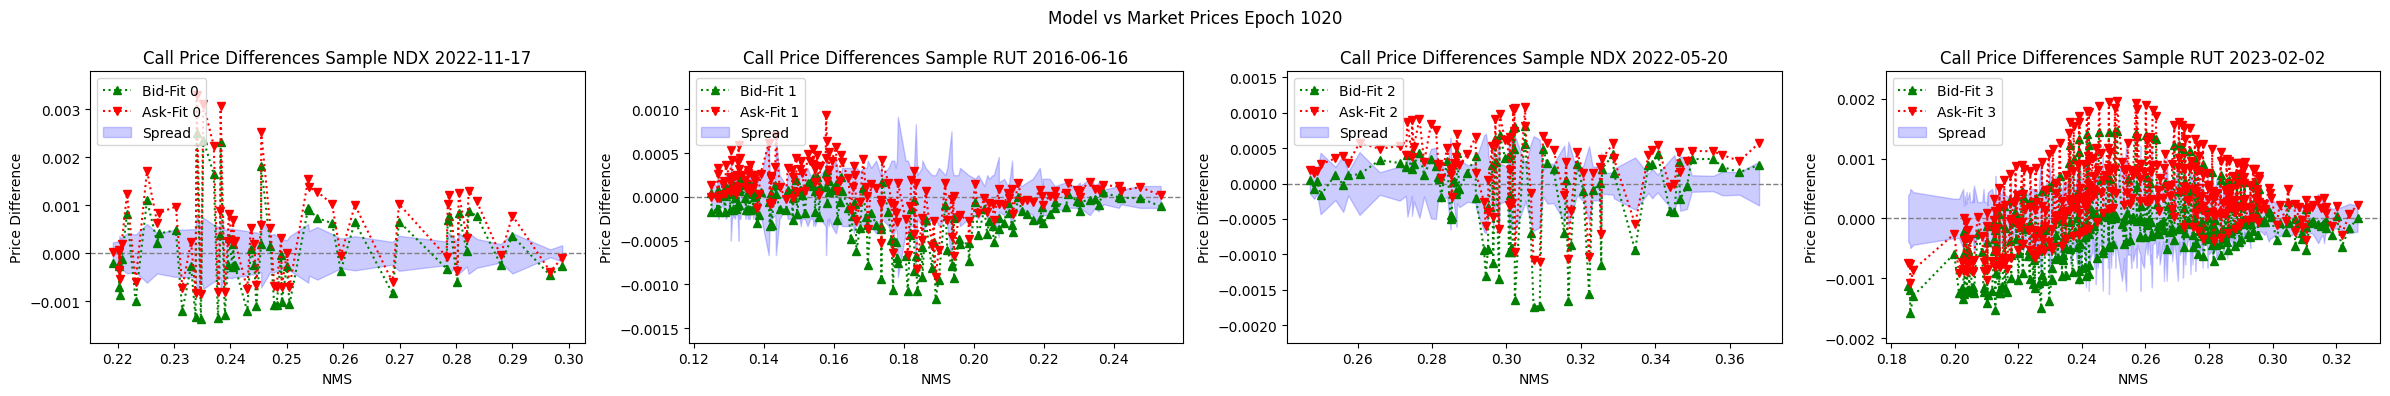

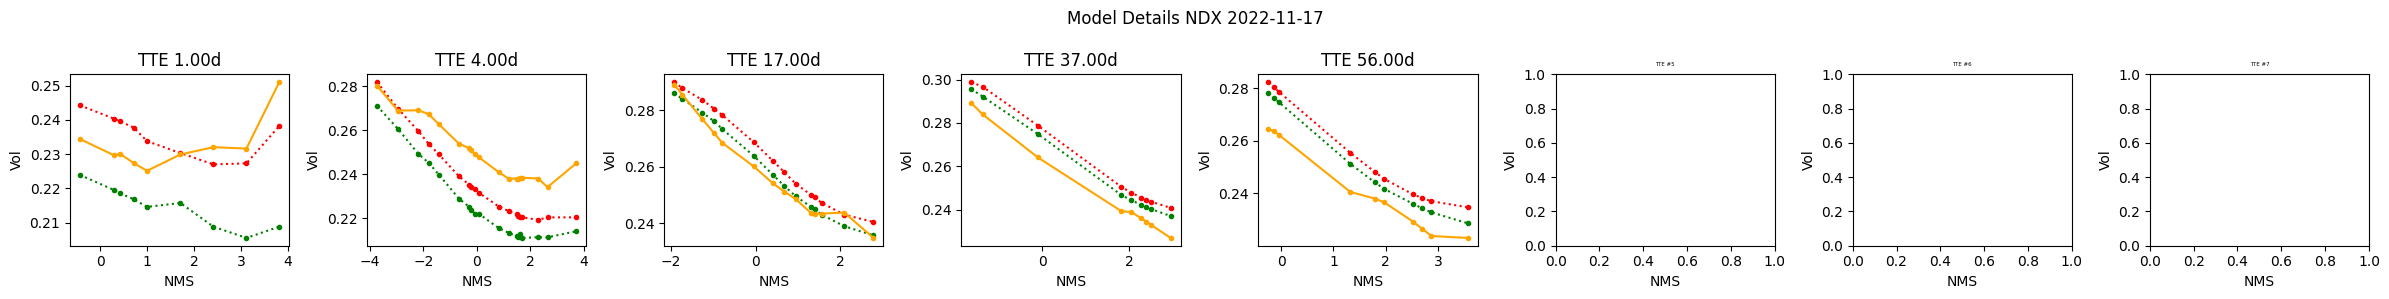

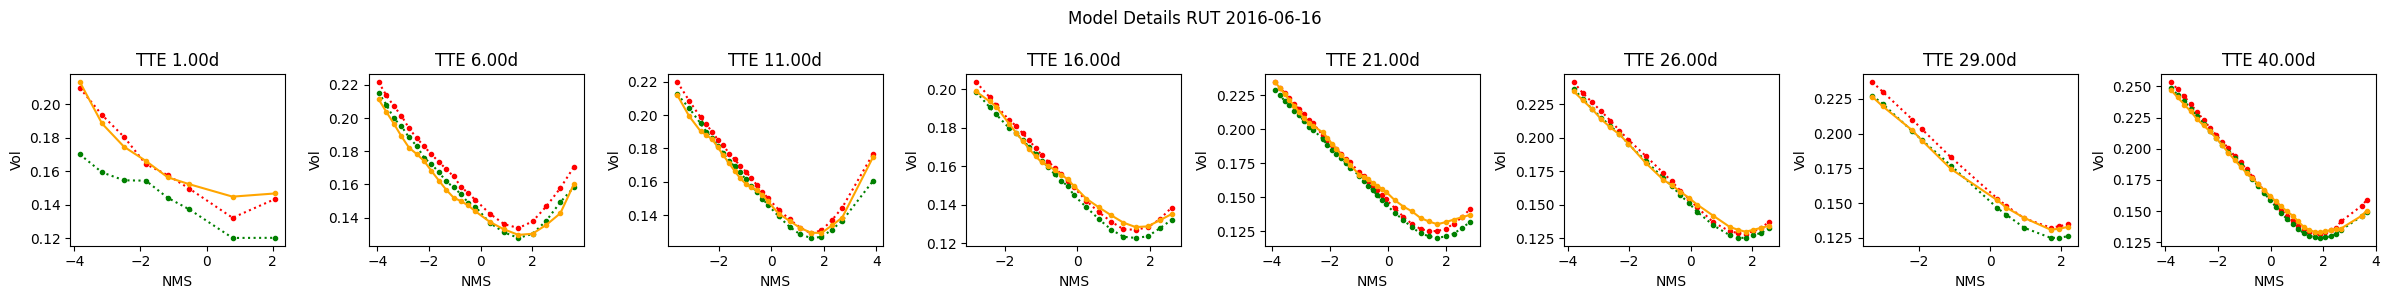

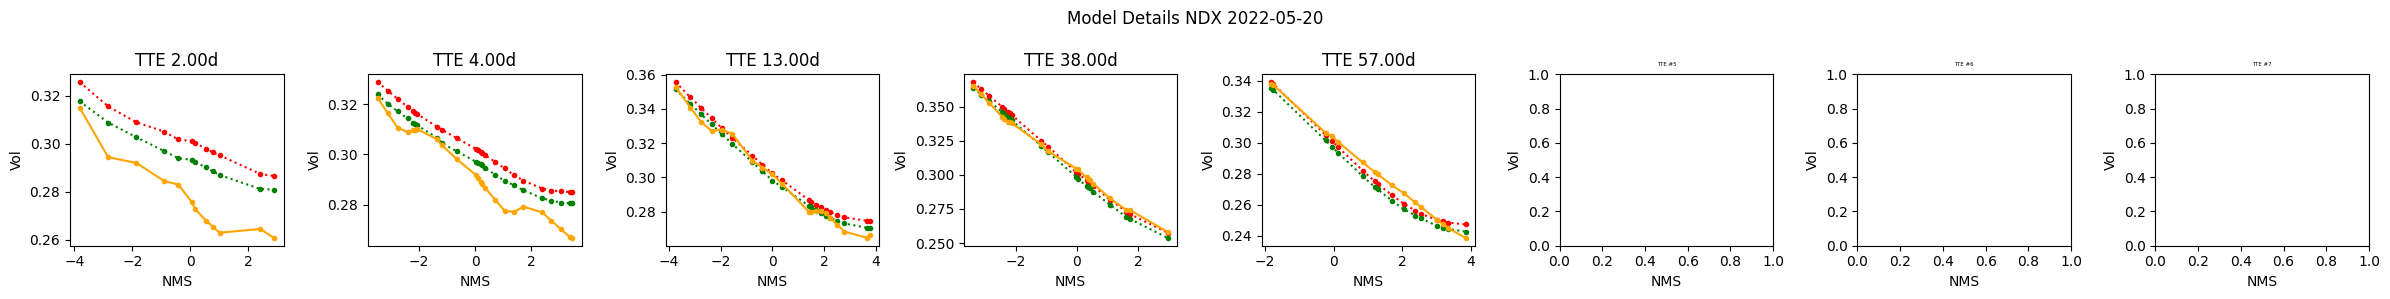

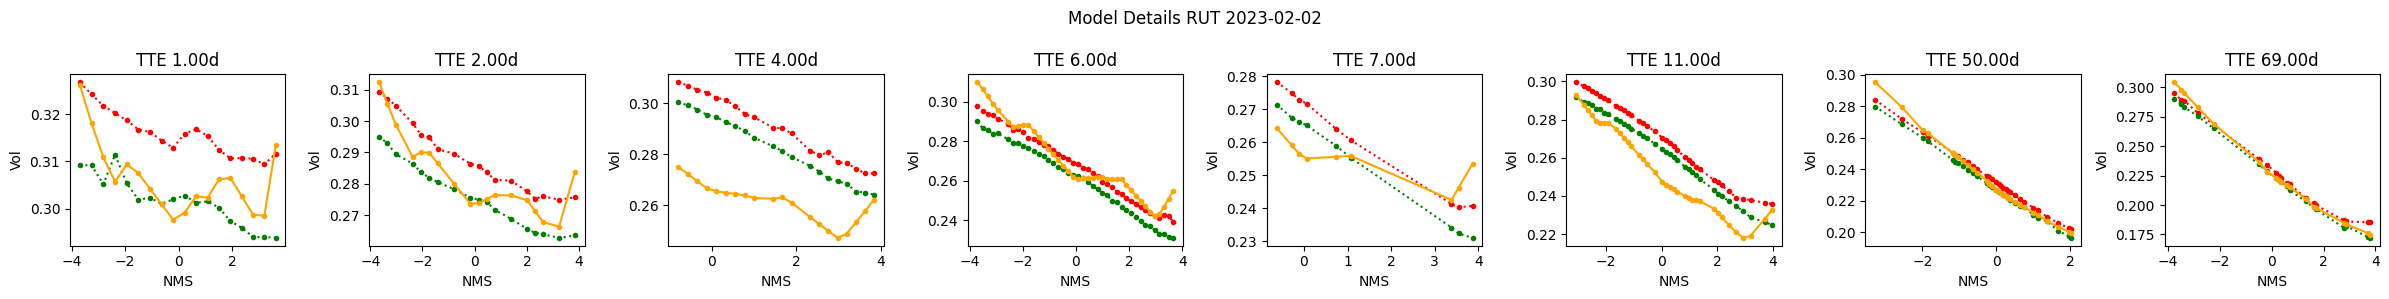

01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/0f5837ec6b870a6d/v1/viz_train_sqrtVar_fit_sqrtVar ed3385ea/last.pt... done; this took 0.05s.
00: Training 'viz_train_sqrtVar_fit_sqrtVar' epoch 1012/1020 error avg trn 0.0007174; val 0.000716/0.001591 [30s 2s 0.51s]. LR: 1.09e-06, GN 0.0005233, excess: 0.0007952/0.001766. ETA: 9:05.
00: Training 'viz_train_sqrtVar_fit_sqrtVar' epoch 1013/1020 error avg trn 0.000715; val 0.0007162/0.001602 [30s 2s 0.51s]. LR: 1.09e-06, GN 0.0006869, excess: 0.0007953/0.001779. ETA: 11:58.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/0f5837ec6b870a6d/v1/viz_train_sqrtVar_fit_sqrtVar ed3385ea/last.pt... done; this took 0.051s.
00: Training 'viz_train_sqrtVar_fit_sqrtVar' epoch 1014/1020 error avg trn 0.0007141; val 0.0007161/0.001586 [30s 2s 0.51s]. LR: 1.08e-06, GN 0.0007697, excess: 0.0007952/0.001761. ETA: 13:41.
00: Training 'viz_train_sqrtVar_fit_sqrtVar' epoch 1015/1020 error avg trn 0.00

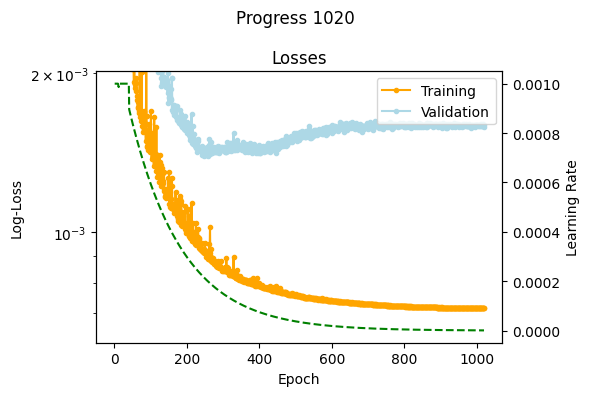

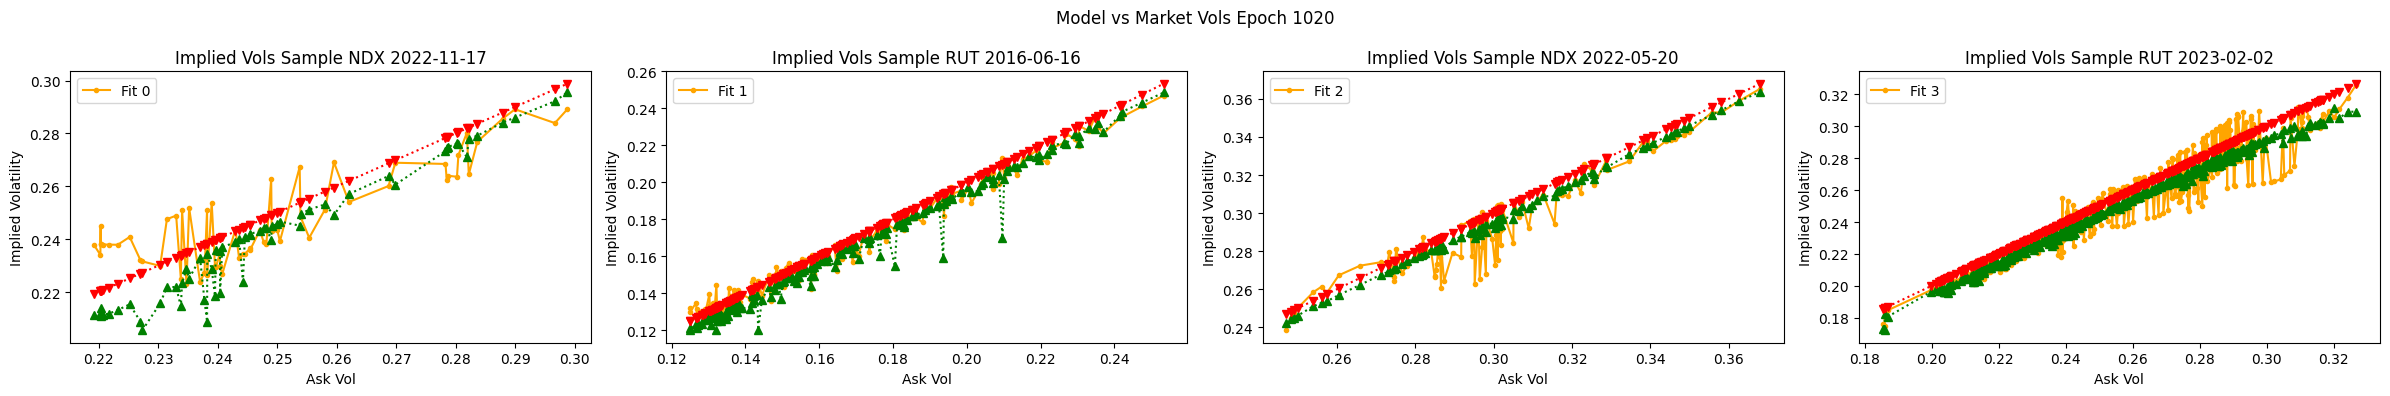

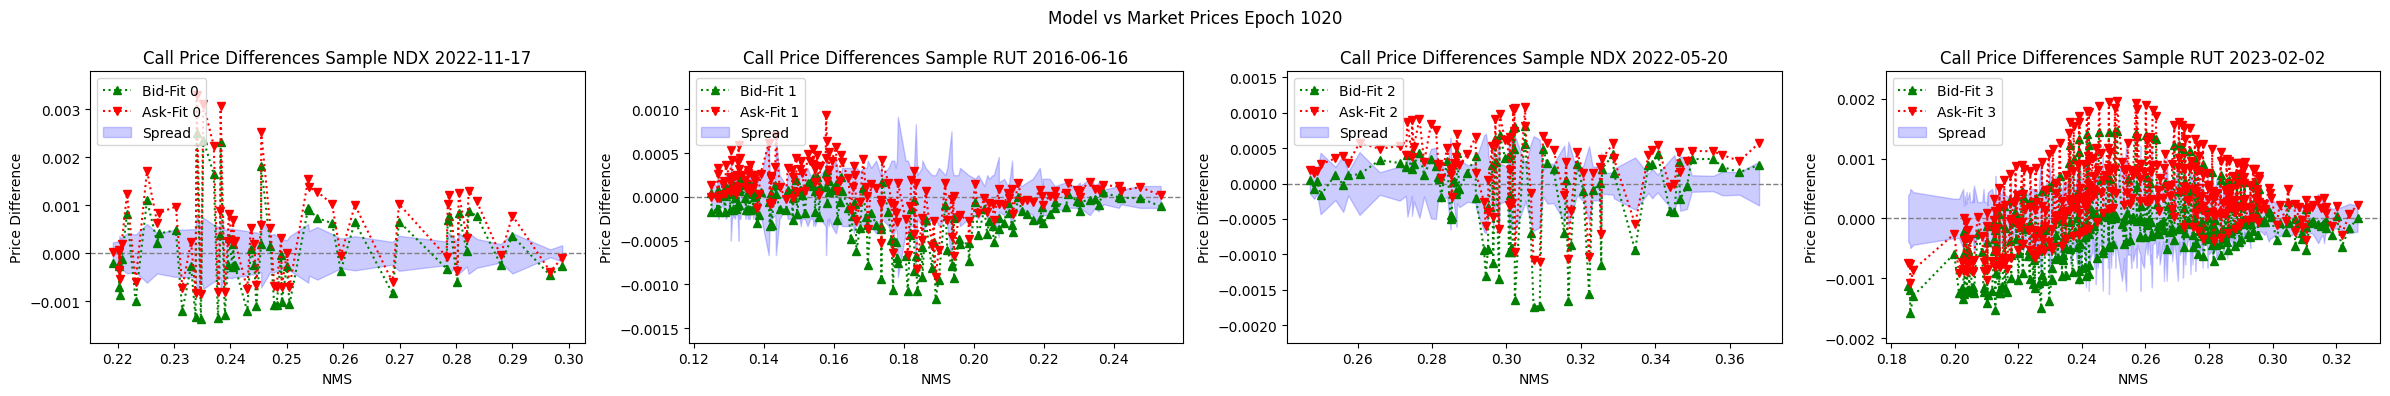

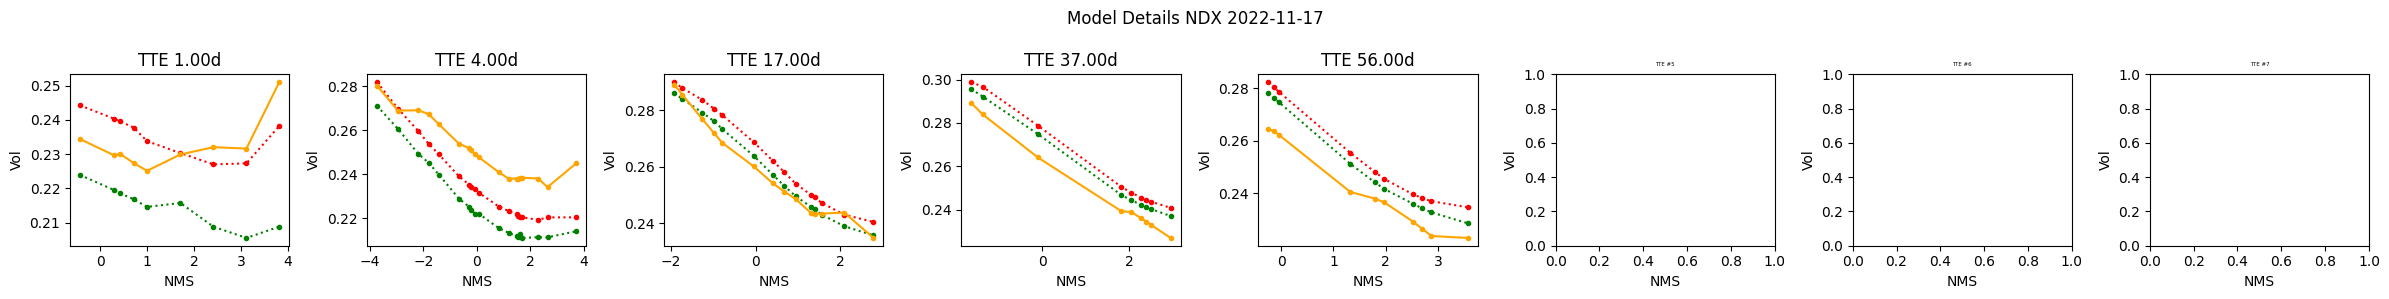

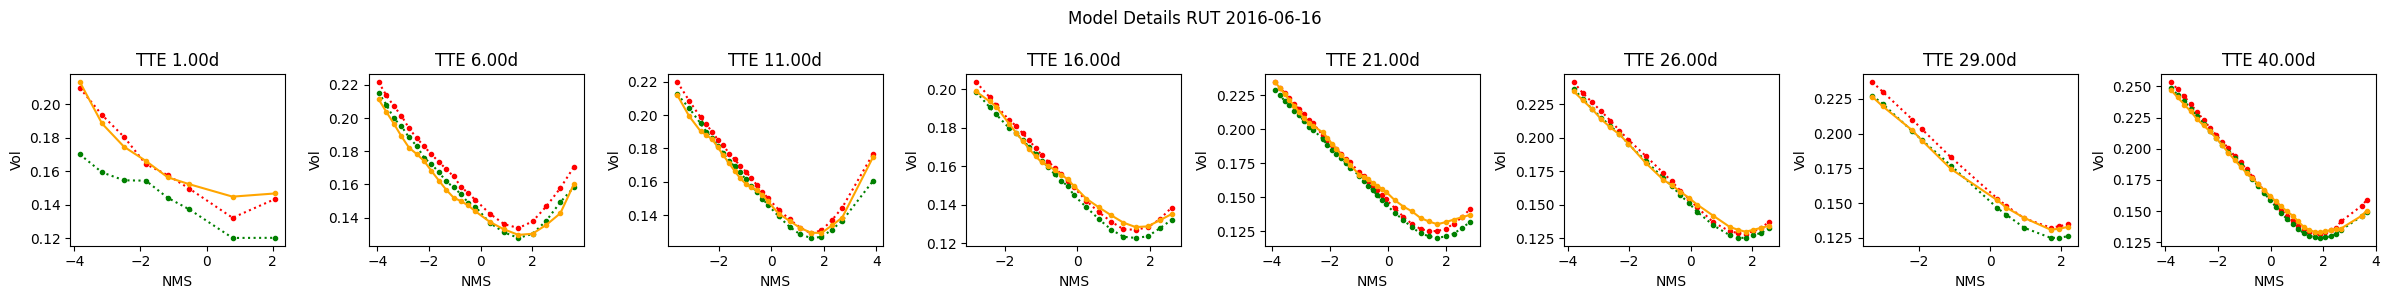

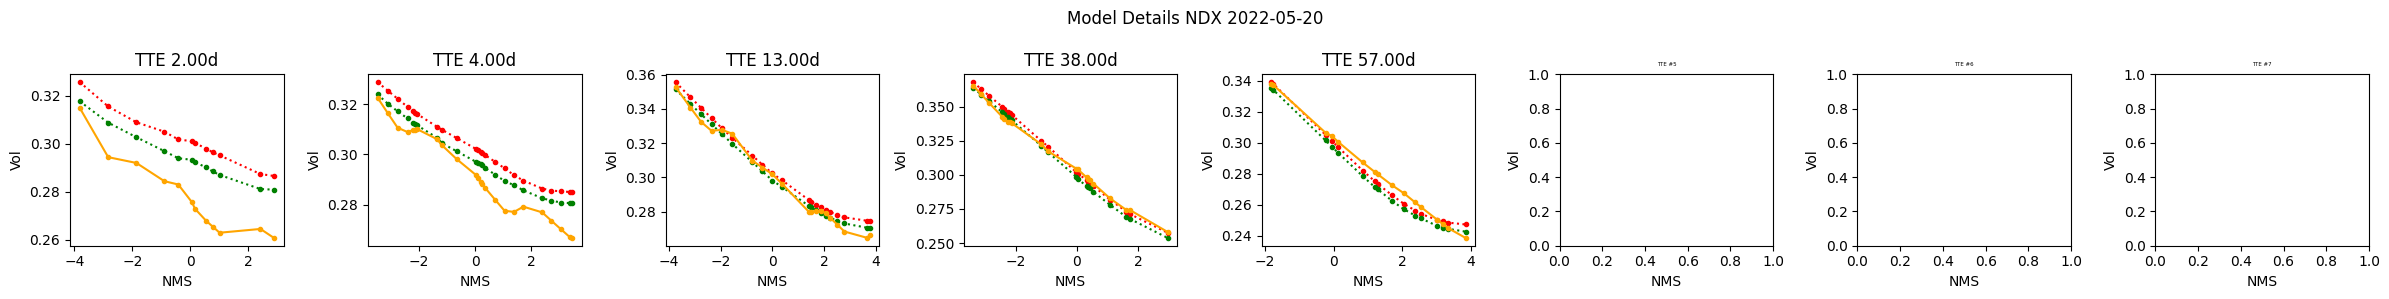

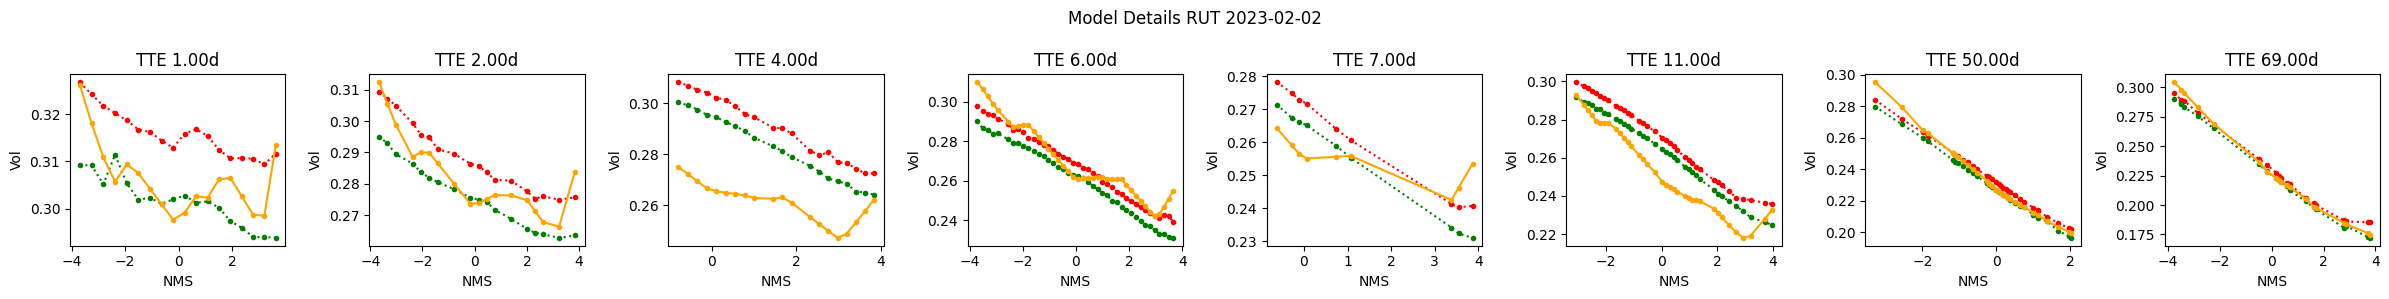

In [2]:
# reloader

%aimport quantdata.utils.add_cdxcore
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer

from quantdata.dysanos.simple.model import AEC, BaseEnvironment, FeedForward
from quantdata.dysanos.simple.trainer import Trainer, TrainConfig
from cdxcore.subdir import SubDir
import ipynbname

env   = BaseEnvironment(device="cuda", debug=False)

aec_config = AEC.Config(
    num_state = 32,
    num_compress = 128   ,
    encode_what = "sqrtVar",
    fit_what="sqrtVar",
    mid_fit_weight = 0.1,
    fit_average = True,
    encoder_set_config = FeedForward.Config(
        num_depth = 2,
        num_width = 32,
        activation = 'ReLU',
    ),
    encoder_fix_config = FeedForward.Config(
        num_depth = 2,
        num_width = 64,
        activation = 'ReLU',
    ),
    decoder_config = FeedForward.Config(
        num_depth = 2,
        num_width = 32,
        activation = 'ReLU',
    ),
    vizualizer_config = AEC.VisualizerConfig(details=True)  # set to None to turn off visualization
)

model = AEC(env=env, 
            sampler=sampler,
            config=aec_config )

print("/model created.")

train_config = TrainConfig(
    lr_init = 1E-3,
    lr_final = 1E-6,
    lr_init_steps = 25,
    trn_batch_size = 128,
    val_batch_size = 2048,
    batch_per_epoch = 100,
    experiment_group="v1"
)

trainer = Trainer( label=ipynbname.name(), model=model, sampler=sampler, config=train_config, verbose=verbose )
_ = trainer(epochs=1020)
